In [8]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Load data
df = pd.read_csv("diamonds.csv")

# 2. Inspect
print("SHAPE")
print(df.shape)

print("\nINFO")
df.info()

print("\nDESCRIBE")
print(df.describe())

print("\nMISSING VALUES")
print(df.isnull().sum())



SHAPE
(53943, 10)

INFO
<class 'pandas.DataFrame'>
RangeIndex: 53943 entries, 0 to 53942
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53943 non-null  str    
 1   cut      53940 non-null  str    
 2   color    53940 non-null  str    
 3   clarity  53940 non-null  str    
 4   depth    53940 non-null  float64
 5   table    53940 non-null  float64
 6   price    53940 non-null  float64
 7   x        53940 non-null  float64
 8   y        53940 non-null  float64
 9   z        53940 non-null  float64
dtypes: float64(6), str(4)
memory usage: 4.9 MB

DESCRIBE
              depth         table         price             x             y  \
count  53940.000000  53940.000000  53940.000000  53940.000000  53940.000000   
mean      61.749405     57.457184   3932.799722      5.731157      5.734526   
std        1.432621      2.234491   3989.439738      1.121761      1.142135   
min       43.000000     43.000000    326.000000 

In [ ]:
# 3. CLEAN DATA
print("\nCLEANING")
original_count = len(df)

df = df.drop_duplicates()
df = df[(df["x"] > 0) & (df["y"] > 0) & (df["z"] > 0)]

cleaned_count = len(df)

print("Original rows:", original_count)
print("Cleaned rows:", cleaned_count)
print("Final Cleaned Shape:", df.shape)



CLEANING
Original rows: 53775
Cleaned rows: 53775
Final Cleaned Shape: (53775, 10)


In [16]:
#1 IQR
q1 = df["price"].quantile(0.25)
q3 = df["price"].quantile(0.75)
iqr = q3 - q1

low = q1 - 1.5 * iqr
high = q3 + 1.5 * iqr

print("Q1", q1)
print("Q3", q3)
print("IQR", iqr)
print("Lower Limit: ", low)
print("Higher Limit: ", high)

outliers = df[(df["price"] < low) | (df["price"] > high)]
print("Total outliers = ", len(outliers))

Q1 951.0
Q3 5324.0
IQR 4373.0
Lower Limit:  -5608.5
Higher Limit:  11883.5
Total outliers =  3520


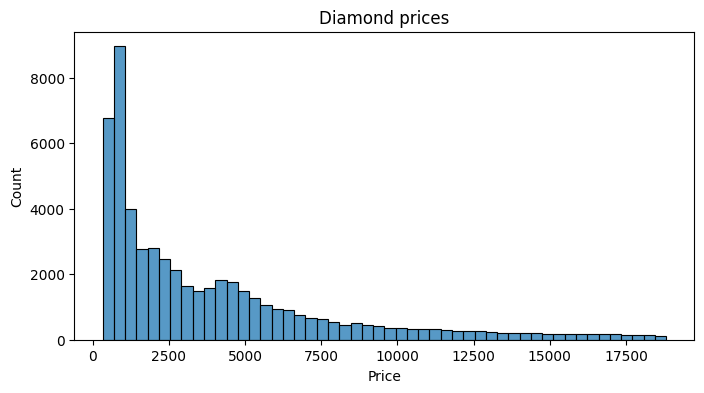

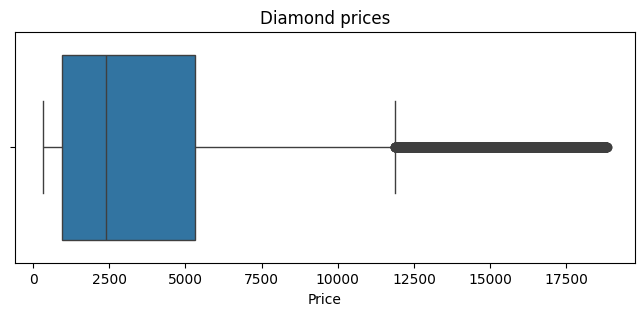

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

#HISTOGRAM
plt.figure(figsize=(8,4))
sns.histplot(df["price"], bins = 50)
plt.title("Diamond prices")
plt.xlabel("Price")
plt.ylabel("Count")
plt.show()

#BOX PLOT
plt.figure(figsize=(8,3))
sns.boxplot(x = df["price"])
plt.title("Diamond prices")
plt.xlabel("Price")
plt.show()

## 5. Findings:
 1. **Finding 1 : (Non-Linear Growth)**
    - **Number:** Diamond prices are not linear, While a 1 carat diamond costs 10000 pkr, a 2 carat diamond cost more then triple 

 2. **Finding 2 : Outliers represent exceptional diamonds**
 - **Number** After the using the IQR rules, 3520 were outliers. But they were not error instead those are high end rare luxury diamonds
 

 

## 6. Conculsion:

1. **What drives a diamond's price?** Physical size and weight('carat', with the dimensions 'x', 'y','z'), these are the primary drivers for the price change.

2. **Are 'Ideal' cut diamonds always the most expensive?** No. Cut quality does affect a little but a smaller diamond with an "ideal" cut will be cheaper then a bigger diamond with a lower grade cut.

3. **Is pricing Linear?** No, pricing is exponential, as the carats increase the price is increased by a lo9t, making larger diamonds more expensive and rare.

4. **What are the price outliers** The outliers identified by using the iqr are not actually outliers, but rare and high end luxury diamonds, they are not errors but legitamate diamonds with very high quality cuts, clarity and dimensions.